In [ ]:
import os
from google.colab import files

os.makedirs('data', exist_ok=True)
uploaded = files.upload()  # Select all .wav files
for fn in uploaded.keys():
    os.replace(fn, os.path.join('data', fn))

Saving segnale.wav to segnale.wav
Saving segnale_2.wav to segnale_2.wav
Saving dati_rumorosi_2.wav to dati_rumorosi_2.wav
Saving dati_rumorosi.wav to dati_rumorosi.wav


In [ ]:
import numpy as np
from scipy.io import wavfile
from scipy.fft import rfft, irfft, rfftfreq

fs, x = wavfile.read('data/dati_rumorosi.wav')
x = x.astype(float)
N = x.size

f = rfftfreq(N, 1/fs)       # frequencies [Hz]
X = rfft(x)                 # N//2 + 1 coefficients

H = np.zeros(f.size)        # the filter
H[(f > 500) & (f < 800)] = 1.0

y = irfft(H * X, n=N)       # back to time
y16 = np.int16(y / np.abs(y).max() * 32767)
wavfile.write('filtered.wav', fs, y16)
print(y16)

[-1443   629  2704 ... -7473 -5513 -3497]


44100 5292000 120.0 13194.051993515872 <built-in method max of numpy.ndarray object at 0x7c46d378b330>


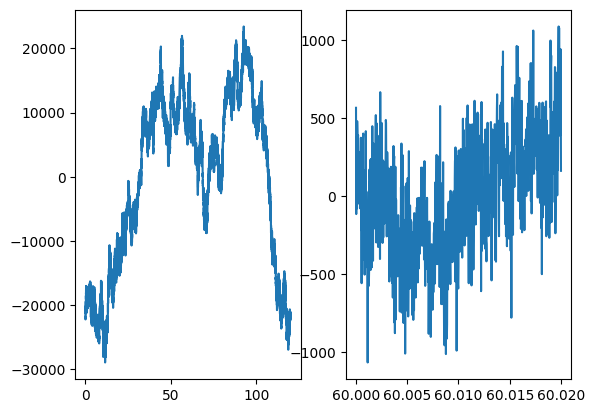

In [ ]:
import matplotlib.pyplot as plt
T = N/fs
t = np.arange(N)/fs
print(fs, N, T, x.std(), np.abs(x).max)

fig, ax = plt.subplots(1, 2)
ax[0].plot(t[::200], x[::200])
z = (t > 60) & (t < 60.02)
ax[1].plot(t[z], x[z] - x[z].mean())
plt.show()

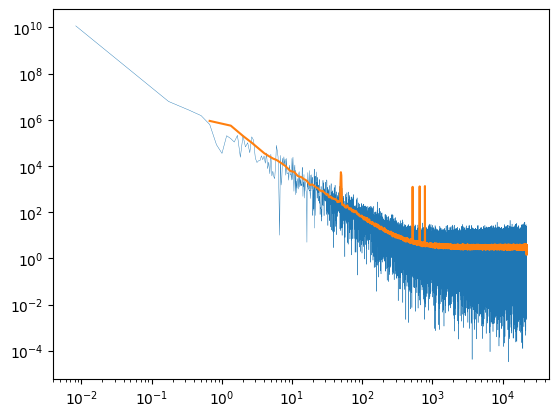

In [ ]:
import scipy.signal as sp

fp, P = sp.periodogram(x, fs)

L = 2**16                                     # 1.49 s
fw, W = sp.welch(x, fs, window='nuttall',
                 nperseg=L)                   # 50% overlap
fb, B = sp.welch(x, fs, window='boxcar',
                 nperseg=L, noverlap=0)       # Bartlett

plt.loglog(fp[1::20], P[1::20], lw=0.3)       # thinned
plt.loglog(fw[1:], W[1:])
plt.show()

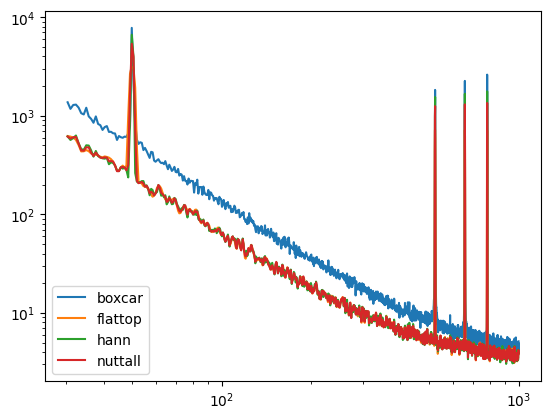

In [ ]:
for win in ['boxcar', 'flattop', 'hann', 'nuttall']:
    fw_w, W_w = sp.welch(x, fs, window=win, nperseg=L)
    sel_z = (fw_w > 30) & (fw_w < 1000)
    plt.loglog(fw_w[sel_z], W_w[sel_z], label=win)
plt.legend()
plt.show()

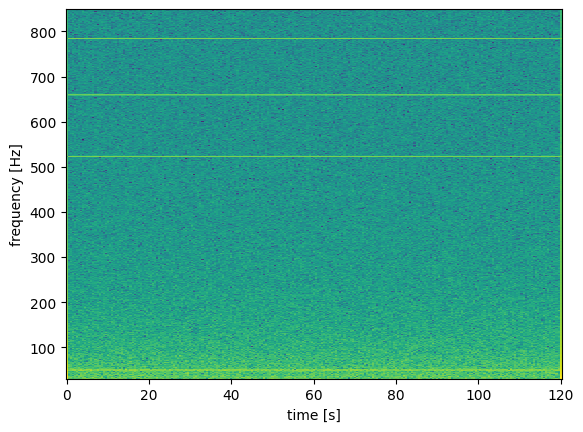

In [ ]:
fq, tt, Z = sp.stft(x, fs, window='hann',
                    nperseg=fs,               # 1 s
                    noverlap=fs // 2)

band = (fq > 30) & (fq < 850)
plt.pcolormesh(tt, fq[band],
               10*np.log10(np.abs(Z[band])**2),
               shading='auto')
plt.xlabel('time [s]')
plt.ylabel('frequency [Hz]')
plt.show()

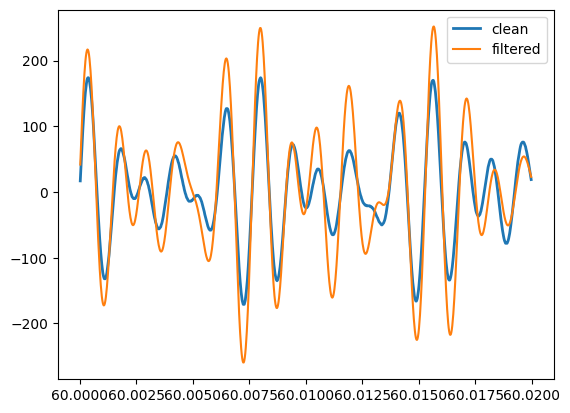

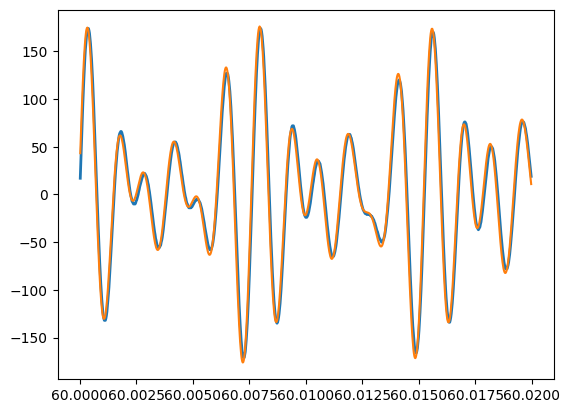

In [ ]:
H = ((f > 493) & (f < 814)).astype(float)
y = irfft(H * X, n=N)

fs, s = wavfile.read('data/segnale.wav')
s = s.astype(float)

z = (t > 60) & (t < 60.02)                    # 20 ms
plt.plot(t[z], s[z], lw=2, label='clean')
plt.plot(t[z], y[z], label='filtered')
plt.legend()
plt.show()

lines = [523.3, 659.3, 784.0]                 # read off the plot
df = 2.5
H = np.zeros(f.size)
for fl in lines:
    H[np.abs(f - fl) < df] = 1.0
y = irfft(H * X, n=N)

plt.plot(t[z], s[z], lw=2); plt.plot(t[z], y[z])
plt.show()

In [ ]:
# Read recording 2 and clean signal 2
fs2, x2 = wavfile.read('data/dati_rumorosi_2.wav')
x2 = x2.astype(float)
_, s2 = wavfile.read('data/segnale_2.wav')
s2 = s2.astype(float)

N2 = x2.size
t2 = np.arange(N2) / fs2
f2 = rfftfreq(N2, 1/fs2)
X2 = rfft(x2)

# Step 1 on Recording 2 (comparing L = 2**16 and L = 2**18 around 434-448 Hz)
fp2, P2 = sp.periodogram(x2, fs2)
fw2_16, W2_16 = sp.welch(x2, fs2, window='nuttall', nperseg=2**16)
fw2_18, W2_18 = sp.welch(x2, fs2, window='nuttall', nperseg=2**18)

plt.semilogy(fp2, P2, lw=0.3, color='gray')
plt.semilogy(fw2_16, W2_16, 'o-', ms=3, label='2**16')
plt.semilogy(fw2_18, W2_18, 'o-', ms=3, label='2**18')
plt.xlim(434, 448)
plt.ylim(1e-5, 1e6)
plt.legend()
plt.show()

# Step 2 on Recording 2 (STFT with 2 s window)
fq2, tt2, Z2 = sp.stft(x2, fs2, window='hann', nperseg=2*fs2, noverlap=fs2)
band2 = (fq2 > 425) & (fq2 < 455)
plt.pcolormesh(tt2, fq2[band2], 10*np.log10(np.abs(Z2[band2])**2), shading='auto')
plt.xlabel('time [s]')
plt.ylabel('frequency [Hz]')
plt.show()

# Step 4 on Recording 2 (Comb with df = 2.5 Hz around 440.0, 442.0, 880.0 Hz)
lines2 = [440.0, 442.0, 880.0]
df = 2.5
H2 = np.zeros(f2.size)
for fl in lines2:
    H2[np.abs(f2 - fl) < df] = 1.0
y2 = irfft(H2 * X2, n=N2)

z2 = (t2 > 60) & (t2 < 60.02)
plt.plot(t2[z2], s2[z2], lw=2); plt.plot(t2[z2], y2[z2])
plt.show()

In [ ]:
from scipy.optimize import curve_fit

# log S_n; A = exp(lA), fk = exp(lfk)
def logS(f, lA, lfk, alpha):
    # log1p(x) = log(1 + x)
    return lA + np.log1p((np.exp(lfk) / f)**alpha)

lines_all = [50.0] + lines
sel = (fw >= 1) & (fw <= 20000)
d = np.abs(fw[:, None] - np.array(lines_all))
far = np.all(d > 10, axis=1)                  # lines out

p, cov = curve_fit(logS, fw[sel & far],
                   np.log(W[sel & far]),
                   p0=[np.log(10), np.log(300), 1.5])
A, fk, alpha = np.exp(p[0]), np.exp(p[1]), p[2]
print(A, fk, alpha)

# Plot data/model against f in log-log (or semilogx)
plt.semilogx(fw[sel & far], W[sel & far] / np.exp(logS(fw[sel & far], *p)))
plt.axhline(1.0, color='k', lw=0.8)
plt.xlabel('frequency [Hz]')
plt.ylabel('data / model')
plt.show()

In [ ]:
# 1. periodogram of the data, density units
P = np.abs(X)**2 * 2 / (fs * N)               # = sp.periodogram

# 2. noise model of step 5 at every frequency fk
Sn = np.exp(logS(np.maximum(f, 1e-3), *p))

# 3. how many times the data exceed the noise
z_snr = P / Sn

# 4. Wiener weights, 0 where z < 1
phi = np.clip(1 - 1 / z_snr, 0, 1)
y_naive = irfft(phi * X, n=N)
print(phi, y_naive)
plt.plot(t[z], y_naive[z], label='filtered data')
plt.plot(t[z], s[z], lw=2, label='clean signal')
plt.legend()
plt.show()

In [ ]:
# 5. the threshold: M bins tested, p false lines
M = np.sum(f > 20)                            # bins tested
zstar = np.log(M / 0.01)                      # p = 0.01 -> 19.4

# 6. the detected lines, without the hum
det = (z_snr > zstar) & (f > 20)
det &= np.abs(f - 50) > 0.5                   # remove 50 Hz
print(f[det])                                 # the lines kept

# 7. Wiener weights only there, 0 elsewhere
H = np.where(det, phi, 0.0)
y_wien = irfft(H * X, n=N)

plt.plot(t[z], s[z], lw=2, label='clean signal')
plt.plot(t[z], y_wien[z], label='filtered data')
plt.legend()
plt.show()

In [ ]:
from scipy.optimize import minimize

far = np.all(np.abs(f[:, None] - np.array(lines_all)) > 2, axis=1)
sel = (f >= 1) & (f <= 20000) & far
fs_, Ps = f[sel], P[sel]

def nll(q):
    S = np.exp(logS(fs_, *q))
    return np.sum(np.log(S) + Ps / S)

r = minimize(nll, p, method='Nelder-Mead')
print(np.exp(r.x[0]), np.exp(r.x[1]), r.x[2])

In [ ]:
from IPython.display import Audio, display

# 1. Recompute all 4 unscaled filtered signals (at original data scale)
# Step 3: Band-pass by eye (493 - 814 Hz)
H_bp = ((f > 493) & (f < 814)).astype(float)
y_bp = irfft(H_bp * X, n=N)

# Step 4: Comb by eye (df = 2.5 Hz around C5, E5, G5)
lines = [523.3, 659.3, 784.0]
H_comb = np.zeros(f.size)
for fl in lines:
    H_comb[np.abs(f - fl) < 2.5] = 1.0
y_comb = irfft(H_comb * X, n=N)

# Step 6a: Naive Wiener (in every bin)
y_naive = irfft(phi * X, n=N)

# Step 6b: Wiener on detected lines (50 Hz removed)
H_wien = np.where(det, phi, 0.0)
y_wien = irfft(H_wien * X, n=N)

# Dictionary of all 4 results
filters = {
    '1_bandpass': ('Step 3: Band-pass by eye (493-814 Hz)', y_bp),
    '2_comb':     ('Step 4: Comb by eye (df = 2.5 Hz)', y_comb),
    '3_naive':    ('Step 6a: Naive Wiener (all bins)', y_naive),
    '4_wiener':   ('Step 6b: Wiener on detected lines', y_wien)
}

# 2. Save all 4 as 16-bit WAV files (normalized to full scale +/-32767 as on Slide 7)
for fname, (title, y_out) in filters.items():
    y16 = np.int16(y_out / np.abs(y_out).max() * 32767)
    wavfile.write(f'{fname}.wav', fs, y16)

# 3. Visual Comparison: 20 ms zoom (t = 60 to 60.02 s) as on Slides 17 & 29
z = (t > 60) & (t < 60.02)
t_ms = (t[z] - 60) * 1e3

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, (fname, (title, y_out)) in zip(axes.flat, filters.items()):
    ax.plot(t_ms, s[z], color='crimson', lw=2, label='clean signal (segnale.wav)')
    ax.plot(t_ms, y_out[z], color='tab:blue', lw=1.2, label='filtered data')
    ax.set_title(title)
    ax.set_xlabel('time [ms] after t = 60 s')
    ax.set_ylabel('sample value')
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

# 4. Quantitative Comparison (RMS of residual error: y_filtered - s_clean)
print(f"{'Filter':<38} | {'Signal RMS':<12} | {'Residual Error RMS':<18}")
print("-" * 74)
print(f"{'Clean reference (segnale.wav)':<38} | {s.std():<12.2f} | {'0.00 (reference)':<18}")
for fname, (title, y_out) in filters.items():
    err_rms = np.std(y_out - s)
    print(f"{title:<38} | {y_out.std():<12.2f} | {err_rms:<18.2f}")

# 5. Listen & Compare Audio Inline (first 5 seconds of each saved .wav file)
print("\n--- LISTEN & COMPARE (First 5 Seconds) ---")
s16_norm = np.int16(s / np.abs(s).max() * 32767)
wavfile.write('0_clean_reference.wav', fs, s16_norm)

print("Reference: Clean Signal (segnale.wav)")
display(Audio('0_clean_reference.wav'))

for fname, (title, _) in filters.items():
    print(f"{title} -> ({fname}.wav)")
    display(Audio(f'{fname}.wav'))